The (published) kinematic model ODEs are
\begin{align*}
    \frac{dr_1}{dt} & = k_1r_t + 2k_2^-r_2 - 2k_2^+r_1^2 - (\lambda_1 + \lambda_c)r_1 \\
    \frac{dr_2}{dt} & = k_2^+r_1^2 + k_3^-r_3 - 2k_3^+r_2S - (k_2^- + \lambda_2 + \lambda_c)r_2 \\
    \frac{dr_3}{dt} & = 2k_3^+r_2S + 2k_4^-r_4 - k_4^+r_3S - (k_3^- + \lambda_3 + \lambda_c)r_3 \\
    \frac{dr_4}{dt} & = k_4^+r_3S - (2k_4^- + \lambda_4 + \lambda_c)r_4 \\
    \frac{ds_a}{dt} & = k_s^+r_4(s_t - s_a) - (k_s^- + \lambda_c)s_a \\
    \frac{dn}{dt} & = b_ns_t + (k_n - b_n)s_a - (k_g + \lambda_n + \lambda_c)n \\
    \frac{dg}{dt} & = k_gn - (\lambda_g + \lambda_c)g.
\end{align*}
The corresponding SDEs have additional noise terms given by $G(\vec{x},t) d\vec{w}(t)$, where $d\vec{w}(t) \in \mathbb{R}^{19}$ and
$$G(\vec{x},t) = \begin{bmatrix}
    G_1(\vec{x},t) & 0 & 0 \\ 0 & G_2(\vec{x},t) & 0 \\ 0 & 0 & G_3(\vec{x},t)
\end{bmatrix}$$
where
\begin{align*}
    G_1(\vec{x},t) & = \begin{bmatrix}
        \sqrt{k_1R_tV} & -\sqrt{(\lambda_1 + \lambda_c)R_1} & -2\sqrt{\frac{k_2^+R_1^2}{V}} & 2\sqrt{k_2^-R_2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
        0 & 0 & \sqrt{\frac{k_2^+R_1^2}{V}} & \sqrt{k_2^-R_2} & -\sqrt{(\lambda_2 + \lambda_c)R_2} & -\sqrt{\frac{2k_3^+R_2S}{V}} & \sqrt{k_3^-R_3} & 0 & 0 & 0 & 0 \\
        0 & 0 & 0 & 0 & 0 & \sqrt{\frac{2k_3^+R_2S}{V}} & -\sqrt{k_3^-R_3} & -\sqrt{(\lambda_3 + \lambda_c)R_3} & -\sqrt{\frac{k_4^+R_3S}{V}} & \sqrt{2k_4^-R_4} & 0 \\
        0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & \sqrt{\frac{k_4^+R_3S}{V}} & -\sqrt{2k_4^-R_4} & -\sqrt{(\lambda_4 + \lambda_c)R_4}
    \end{bmatrix}, \\
    G_2(\vec{x},t) & = \begin{bmatrix} \sqrt{\frac{k_S^+R_4(S_t - S_a)}{V}} & -\sqrt{k_S^-S_a} & -\sqrt{\lambda_c S_a} \end{bmatrix}, \\
    G_3(\vec{x},t) & = \begin{bmatrix}
        \sqrt{b_nS_tV} & \sqrt{(k_n - b_n)S_aV} & -\sqrt{(\lambda_n + \lambda_c)N} & -\sqrt{k_gN} & 0 \\
        0 & 0 & 0 & \sqrt{k_gN} & -\sqrt{(\lambda_g + \lambda_c)G}
    \end{bmatrix}.
\end{align*}
However, some components (namely $R_2$, $R_3$, $R_4$, and $S_a$) have a large amount of noise compared to their average molecule count, meaning that the SDE trajectories frequently cross zero. This is unphysical, and suggests that SDEs are the wrong approach for these components. Here, I include a Gillespie algorithm for this system. While it will be extremely slow, the SDE trajectories appear to reach a steady-state distribution after a short amount of time ($\approx 1$ hour), so the simulations will not need to be extremely long.

In [1]:
import numpy as np

t_d = 3 # Average cell cycle duration (hours); 3 is fast-growing.
lambda_c = np.log(2) / t_d # cell-cycle dependent protein degradation rate
lambda_d = 0.113 # lasR dimer degradation rate
lambda_gfp = 0.107

a = 349.30
lasR_production_rate = a + ((1000 - a)/0.231)*lambda_c # cell-cycle dependent protein production, used for k_1 and k_n
k_d_off = 3758 # off rates for lasR dimers, k_2-, k_3-, k_4-
k_d_on = 235.019 # on rates for lasR dimers with signals bound, k_3+, k_4+

K_s = 1.229 # complex DNA dissociation constant
k_s_m = 0.044
k_s_p = k_s_m / K_s

V = 1 # Relative cell volume. V = 1 (i.e., the cell volume is approx 1.66e-18 L = 1.66 fL) gives the ODEs for the concentrations.

lambda_dictionary = {
    'lambda_1': 8.975,
    'lambda_2': lambda_d,
    'lambda_3': lambda_d,
    'lambda_4': lambda_d,
    'lambda_n': lambda_gfp,
    'lambda_g': lambda_gfp,
    'lambda_c': lambda_c,
}

k_dictionary = {
    'k_1': lasR_production_rate,
    'k_2_p': 1.490,
    'k_2_m': k_d_off, 
    'k_3_p': k_d_on, 
    'k_3_m': k_d_off, 
    'k_4_p': k_d_on, 
    'k_4_m': k_d_off, 
    'k_s_p': k_s_p, 
    'k_s_m': k_s_m, 
    'k_n': lasR_production_rate, 
    'k_g': 7.709,
}

pars = {
    'lambda_dictionary': lambda_dictionary,
    'k_dictionary': k_dictionary,
    'b_n': 0, # baseline production of gfp protein
    'R_t': 1, # genomic lasR concentration
    'S_t': 8.986, # copy count of signal production genes
    'I_0': 5, # initial intensity in experiment (not given in paper)
    'A': 0.002,
    'V': V,
}

def gfp_to_luminescence(gfp_time_series):
    return pars['I_0'] + pars['A']*gfp_time_series

In [187]:
import numpy as np
import sys

def print_progress(t, tmax, label):
    n_bar = 50  # Progress bar width
    progress = t / tmax
    sys.stdout.write(f"\r[{'=' * int(n_bar * progress):{n_bar}s}] {int(100 * progress)}% {label}")
    sys.stdout.flush() # Forces the output to be written immediately

def kinetic_ODEs(t, x, signal_fun, pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    R_t = pars['R_t']
    S_t = pars['S_t']
    V = pars['V']

    R_1, R_2, R_3, R_4, S_a, N, G = np.maximum(np.zeros((7)), x)

    S = signal_fun(t)

    dR1_dt = k_1*R_t*V + 2*k_2_m*R_2 - 2*k_2_p*(R_1**2)/V - (lambda_1 + lambda_c)*R_1
    dR2_dt = k_2_p*(R_1**2)/V + k_3_m*R_3 - 2*k_3_p*R_2*S/V - (k_2_m + lambda_2 + lambda_c)*R_2
    dR3_dt = 2*k_3_p*R_2*S/V + 2*k_4_m*R_4 - k_4_p*R_3*S/V - (k_3_m + lambda_3 + lambda_c)*R_3
    dR4_dt = k_4_p*R_3*S/V - (2*k_4_m + lambda_4 + lambda_c)*R_4
    dS_a_dt = k_s_p*R_4*(S_t - S_a)/V - (k_s_m + lambda_c)*S_a
    dN_dt = b_n*S_t*V + (k_n - b_n)*S_a*V - (k_g + lambda_n + lambda_c)*N
    dG_dt = k_g*N - (lambda_g + lambda_c)*G

    return np.array([dR1_dt, dR2_dt, dR3_dt, dR4_dt, dS_a_dt, dN_dt, dG_dt])

def get_rates(t, x, signal_fun, pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    R_t = pars['R_t']
    S_t = pars['S_t']
    V = pars['V']

    R_1, R_2, R_3, R_4, S_a, N, G = np.maximum(np.zeros((7)), x)
    S_a = min(S_a, S_t) # ensure S_a doesn't exceed S_t

    S = signal_fun(t)

    p1 = k_1*R_t*V
    r1to2 = k_2_p*(R_1**2)/V
    r2to1 = k_2_m*R_2
    d1 = (lambda_1 + lambda_c)*R_1
    r2to3 = 2*k_3_p*R_2*S/V
    r3to2 = k_3_m*R_3
    d2 = (lambda_2 + lambda_c)*R_2
    r3to4 = k_4_p*R_3*S/V
    r4to3 = 2*k_4_m*R_4
    d3 = (lambda_3 + lambda_c)*R_3
    d4 = (lambda_4 + lambda_c)*R_4

    pS = k_s_p*R_4*(S_t - S_a)/V
    dS = (k_s_m + lambda_c)*S_a

    pN = b_n*S_t*V + (k_n - b_n)*S_a*V
    rNtoG = k_g*N
    dN = (lambda_n + lambda_c)*N
    dG = (lambda_g + lambda_c)*G

    rates = np.array([p1, r1to2, r2to1, d1, r2to3, r3to2, d2, r3to4, r4to3, d3, d4, pS, dS, pN, rNtoG, dN, dG])

    return rates

def gillespie_step(t, x, signal_fun, pars):
    rates = get_rates(t, x, signal_fun, pars)
    total_rate = np.sum(rates)
    if total_rate == 0:
        return t + 1e-6, x # no reactions can occur, so just advance time slightly
    dt = np.random.exponential(1 / total_rate) # the change in time is exponentially distributed with mean 1/total_rate
    reaction_index = np.random.choice(len(rates), p=rates/total_rate) # choose a reaction to occur with probability proportional to its rate
    
    # Define the state change for each reaction
    state_changes = np.array([[1,  0,  0,  0,  0,  0,  0],   # p1
                              [-2, 1,  0,  0,  0,  0,  0],   # r1to2
                              [2, -1,  0,  0,  0,  0,  0],   # r2to1
                              [-1, 0,  0,  0,  0,  0,  0],   # d1
                              [0, -1,  1,  0,  0,  0,  0],   # r2to3
                              [0,  1, -1,  0,  0,  0,  0],   # r3to2
                              [0, -1,  0,  0,  0,  0,  0],   # d2
                              [0,  0, -1,  1,  0,  0,  0],   # r3to4
                              [0,  0,  1, -1,  0,  0,  0],   # r4to3
                              [0,  0, -1,  0,  0,  0,  0],   # d3 (affects all species)
                              [0,  0,  0, -1,  0,  0,  0],   # d4 (affects all species)
                              [0,  0,  0,  0,  1,  0,  0],   # pS
                              [0,  0,  0,  0, -1,  0,  0],   # dS
                              [0,  0,  0,  0,  0,  1,  0],   # pN
                              [0,  0,  0,  0,  0, -1,  1],   # rNtoG
                              [0,  0,  0,  0,  0, -1,  0],   # dN
                              [0,  0,  0,  0,  0,  0, -1]])  # dG
    
    x_new = x + state_changes[reaction_index] # update the state based on the chosen reaction
    return t + dt, x_new

def gillespie_simulation(tmax, x0, signal_fun, pars):
    buffer_len = 10000 # preallocate buffers for time and state values
    t_values = np.zeros(buffer_len)
    x_values = np.zeros((7, buffer_len))
    t_values[0] = 0
    x_values[:, 0] = x0
    t, x = 0, x0
    index = 1
    while t < tmax:
        t, x = gillespie_step(t, x, signal_fun, pars)
        if index % buffer_len == 0: # if we've filled the buffer, expand it
            t_values = np.concatenate((t_values, np.zeros(buffer_len)))
            x_values = np.concatenate((x_values, np.zeros((7, buffer_len))), axis=1)
            print_progress(t, tmax, 'Simulating Gillespie (SSA) trajectory...')

        t_values[index] = t
        x_values[:,index] = x
        index += 1
    
    print_progress(len(t_values), len(t_values), 'Gillespie (SSA) simulation complete.' + ' '*20)
    #print('\rSimulation complete.', end=80*' ')
    sys.stdout.flush()
    
    return t_values[:index], x_values[:,:index]

In [60]:
tmax = 16
init_cond = [0, 0, 0, 0, 0, 0, 0]
s_fun = lambda t: 100 if t <= 6 else 0

t, x = gillespie_simulation(tmax=tmax, x0=init_cond, signal_fun=s_fun, pars=pars)

[==================================================] 100% Simulation complete.                    

In [61]:
from scipy.integrate import solve_ivp

odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

sys.stdout.write('Solving ODE...')
sol = solve_ivp(odefun, [0, tmax], init_cond, t_eval=np.linspace(0, tmax, 1000))
t_ODE, x_ODE = sol.t, sol.y
sys.stdout.write('\rODE solution complete.' + ' '*20 + '\n')
sys.stdout.flush()

ODE solution complete.                    


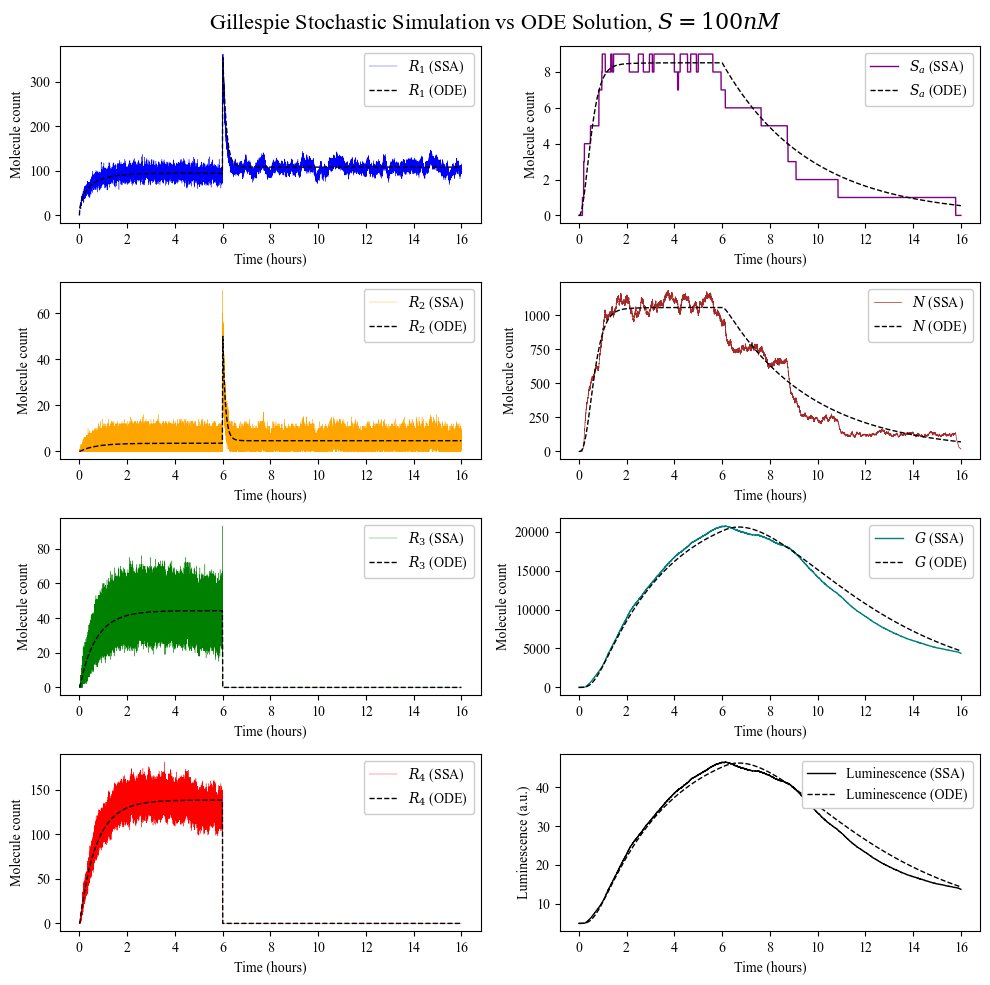

In [126]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

fig, axes = plt.subplots(4, 2, figsize=(10, 10), dpi=100, layout='tight')

labels = [r'$R_1$', r'$R_2$', r'$R_3$', r'$R_4$', r'$S_a$', r'$N$', r'$G$', r'Luminescence']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'teal', 'black']
plot_linewidths = [0.25, 0.25, 0.25, 0.25, 1, 0.5, 1, 1]

axes[3,1].plot(t, gfp_to_luminescence(x[6,:]), label=labels[7] + ' (SSA)', color=colors[7], linewidth=plot_linewidths[7])
axes[3,1].plot(t_ODE, gfp_to_luminescence(x_ODE[6,:]), label=labels[7] + ' (ODE)', color='black', linestyle='--', linewidth=1)
axes[3,1].set_xlabel('Time (hours)')
axes[3,1].set_ylabel('Luminescence (a.u.)')
axes[3,1].legend(loc='upper right', fontsize=10, framealpha=1)

for n in range(7):
    i, j = n % 4, n // 4
    axes[i,j].plot(t, x[n,:], label=labels[n] + ' (SSA)', color=colors[n], linewidth=plot_linewidths[n])
    axes[i,j].plot(t_ODE, x_ODE[n,:], label=labels[n] + ' (ODE)', color='black', linestyle='--', linewidth=1)
    axes[i,j].set_xlabel('Time (hours)')
    axes[i,j].set_ylabel('Molecule count')
    axes[i,j].legend(loc='upper right', fontsize=10, framealpha=1)

fig.suptitle(r'Gillespie Stochastic Simulation vs ODE Solution, $S = 100 nM$', fontsize=16)

plt.savefig('Figures/gillespie_simulation_S=100.png', bbox_inches='tight', dpi=300)

Analysis of the distribution of $R_4(t)$.

In [208]:
tmax = 40
init_cond = [0, 0, 0, 0, 0, 0, 0]
s_fun = lambda t: 10

t_SSA, x_SSA = gillespie_simulation(tmax=tmax, x0=init_cond, signal_fun=s_fun, pars=pars)

[==================================================] 100% Gillespie (SSA) simulation complete.                    

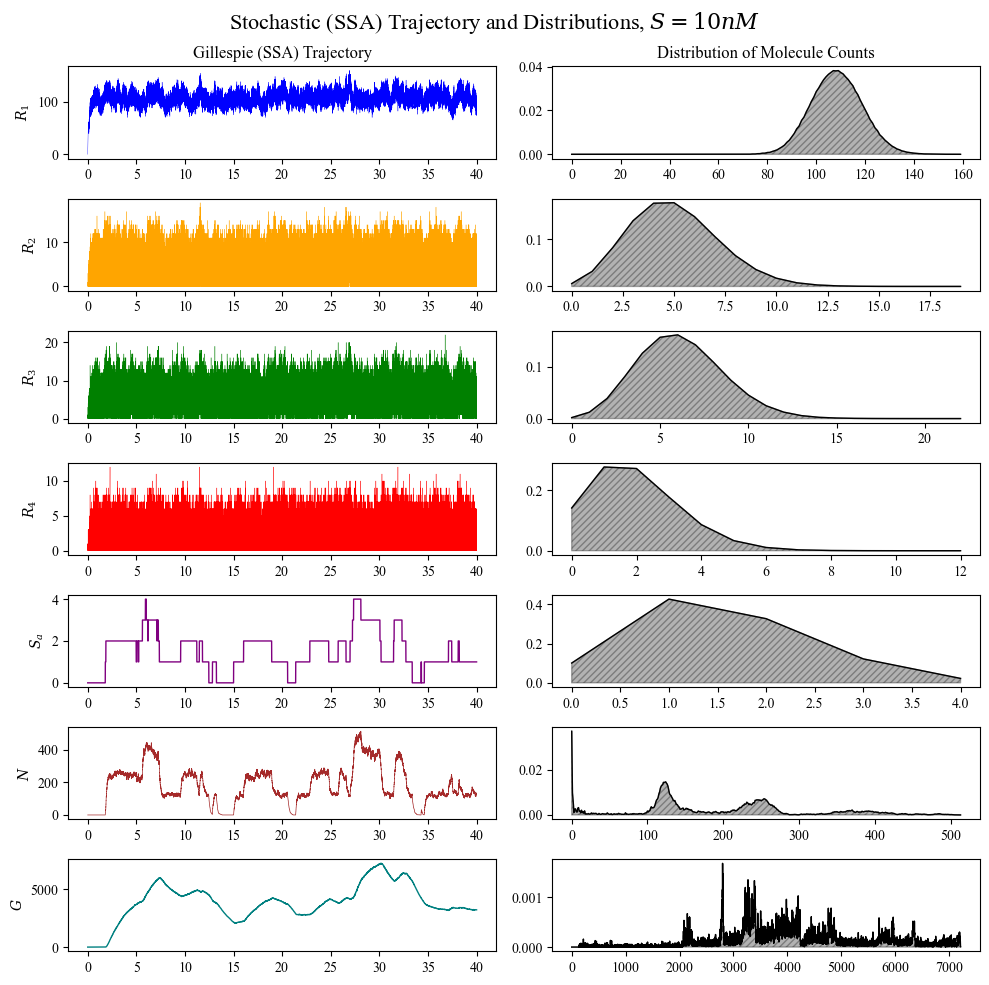

In [209]:
SSA_test_indices = np.where((t_SSA >= 2) & (t_SSA <= tmax))[0]

SSA_test_values = x_SSA[:, SSA_test_indices]

SSA_max_values = np.max(SSA_test_values, axis=1).astype(int)

SSA_bins = [np.arange(-0.5, max_val + 1.5, 1) for max_val in SSA_max_values] # bins for histogram, from -0.5 to max+0.5 with width 1

SSA_histograms = []
SSA_bin_edges_list = []

for n in range(7):
    hist, bin_edges = np.histogram(SSA_test_values[n,:], bins=SSA_bins[n], density=True)
    SSA_histograms.append(hist)
    SSA_bin_edges_list.append(bin_edges)

fig, axes = plt.subplots(7, 2, figsize=(10,10), dpi=100, layout='tight')

for n in range(7):
    axes[n,0].plot(t_SSA, x_SSA[n,:], color=colors[n], linewidth=plot_linewidths[n])
    axes[n,1].plot(SSA_bin_edges_list[n][:-1] + 0.5, SSA_histograms[n], color='black', linestyle='-', linewidth=1)
    axes[n,1].fill_between(SSA_bin_edges_list[n][:-1] + 0.5, SSA_histograms[n], alpha=0.3, color='black', hatch='/////', edgecolor='black')
    axes[n,0].set_ylabel(labels[n])

axes[0,0].set_title('Gillespie (SSA) Trajectory')
axes[0,1].set_title('Distribution of Molecule Counts')

fig.suptitle(r'Stochastic (SSA) Trajectory and Distributions, $S = 10 nM$', fontsize=16)
plt.savefig('Figures/SSA_trajectory_and_distributions.png', dpi=300, bbox_inches='tight')

### Comparing distributions from the SSA to those from the CLE

In [190]:
'''Functions for SDE Numerical Methods'''

from scipy.optimize import root
from scipy.linalg import block_diag

def generate_constant_G_matrix(g_values):
    g_1, g_2, g_3, g_4, g_5, g_6, g_7, g_8, g_9, g_10, g_11, g_12, g_13, g_14, g_15, g_16, g_17, g_18, g_19 = g_values

    G1 = np.array([[g_1,    -g_2,   -2*g_3, 2*g_4,    0,      0,      0,      0,      0,      0,      0],
                   [0,      0,      g_3,    -g_4,   -g_5,   -g_6,   g_7,    0,      0,      0,      0],
                   [0,      0,      0,      0,      0,      g_6,    -g_7,   -g_8,   -g_9,   g_10,   0],
                   [0,      0,      0,      0,      0,      0,      0,      0,      g_9,    -g_10,  -g_11]])
    G2 = np.array([[g_12, -g_13, -g_14]])
    G3 = np.array([[g_15,   g_16,   -g_17,  -g_18,  0],
                   [0,      0,      0,      g_18,   -g_19]])
    
    return block_diag(G1, G2, G3)

def get_constant_G_matrix(pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    R_t = pars['R_t']
    S_t = pars['S_t']
    V = pars['V']

    g_1 = k_1*R_t*V
    g_2 = (lambda_1 + lambda_c)
    g_3 = k_2_p/V
    g_4 = k_2_m
    g_5 = (lambda_2 + lambda_c)
    g_6 = 2*k_3_p/V
    g_7 = k_3_m
    g_8 = (lambda_3 + lambda_c)
    g_9 = k_4_p/V
    g_10 = 2*k_4_m
    g_11 = (lambda_4 + lambda_c)

    g_12 = k_s_p/V
    g_13 = (k_s_m)
    g_14 = lambda_c

    g_15 = b_n*S_t*V
    g_16 = (k_n - b_n)*V
    g_17 = (lambda_n + lambda_c)
    g_18 = k_g
    g_19 = (lambda_g + lambda_c)

    g_values = np.sqrt(np.array([g_1, g_2, g_3, g_4, g_5, g_6, g_7, g_8, g_9, g_10, g_11, g_12, g_13, g_14, g_15, g_16, g_17, g_18, g_19]))
    
    return generate_constant_G_matrix(g_values)

def update_G_matrix(t, x, G, G_constants, signal_fun, pars):
    R_1_sqrt, R_2_sqrt, R_3_sqrt, R_4_sqrt, S_a_sqrt, N_sqrt, G_sqrt = np.sqrt(np.maximum(np.zeros((7)), x))
    S_a = x[4]
    S_sqrt = np.sqrt(signal_fun(t))

    G[0,0] = G_constants[0,0] # update g_1
    G[0,1] = G_constants[0,1] * R_1_sqrt # update g_2
    G[0,2] = G_constants[0,2] * (R_1_sqrt**2) # update g_3
    G[0,3] = G_constants[0,3] * R_2_sqrt # update g_4
    G[1,2] = G_constants[1,2] * (R_1_sqrt**2) # update g_3
    G[1,3] = G_constants[1,3] * R_2_sqrt # update g_4
    G[1,4] = G_constants[1,4] * R_2_sqrt # update g_5
    G[1:3,5] = G_constants[1:3,5] * R_2_sqrt * S_sqrt # update g_6
    G[1:3,6] = G_constants[1:3,6] * R_3_sqrt # update g_7
    G[2,7] = G_constants[2,7] * R_3_sqrt # update g_8
    G[2:4,8] = G_constants[2:4,8] * R_3_sqrt * S_sqrt # update g_9
    G[2:4,9] = G_constants[2:4,9] * R_4_sqrt # update g_10
    G[3,10] = G_constants[3,10] * R_4_sqrt # update g_11

    G[4,11] = G_constants[4,11] * R_4_sqrt * np.sqrt(max(pars['S_t'] - S_a, 0)) # update g_12
    G[4,12] = G_constants[4,12] * S_a_sqrt # update g_13
    G[4,13] = G_constants[4,13] * S_a_sqrt # update g_14
    
    G[5,14] = G_constants[5,14] # update g_15
    G[5,15] = G_constants[5,15] * S_a_sqrt # update g_16
    G[5,16] = G_constants[5,16] * N_sqrt # update g_17
    G[5:7,17] = G_constants[5:7,17] * N_sqrt # update g_18
    G[6,18] = G_constants[6,18] * G_sqrt # update g_19

    return G

def get_dw(x, dt):
    dw = np.random.normal(size=19) * np.sqrt(dt)
    if x[0] < 0: # if R_1 is negative, set all noise terms involving R_1 to be greater than zero
        dw[0] = max(dw[0], 0) # if R_1 is negative, set g_1 noise term to be greater than zero
        dw[1] = min(dw[1], 0) # if R_1 is negative, set g_2 noise term to be greater than zero
        dw[2] = min(dw[2], 0) # if R_1 is negative, set g_3 noise term to be greater than zero
        dw[3] = max(dw[3], 0) # if R_1 is negative, set g_4 noise term to be greater than zero
    if x[1] < 0: # if R_2 is negative, set all noise terms involving R_2 to be greater than zero
        dw[2] = max(dw[2], 0) # if R_2 is negative, set g_3 noise term to be greater than zero
        dw[3] = min(dw[3], 0) # if R_2 is negative, set g_4 noise term to be greater than zero
        dw[4] = min(dw[4], 0) # if R_2 is negative, set g_5 noise term to be greater than zero
        dw[5] = min(dw[5], 0) # if R_2 is negative, set g_6 noise term to be greater than zero
        dw[6] = max(dw[6], 0) # if R_2 is negative, set g_7 noise term to be greater than zero
    if x[2] < 0: # if R_3 is negative, set all noise terms involving R_3 to be greater than zero
        dw[5] = max(dw[5], 0) # if R_3 is negative, set g_6 noise term to be greater than zero
        dw[6] = min(dw[6], 0) # if R_3 is negative, set g_7 noise term to be greater than zero
        dw[7] = min(dw[7], 0) # if R_3 is negative, set g_8 noise term to be greater than zero
        dw[8] = min(dw[8], 0) # if R_3 is negative, set g_9 noise term to be greater than zero
        dw[9] = max(dw[9], 0) # if R_3 is negative, set g_10 noise term to be greater than zero
    if x[3] < 0: # if R_4 is negative, set all noise terms involving R_4 to be greater than zero
        dw[8] = max(dw[8], 0) # if R_4 is negative, set g_9 noise term to be greater than zero
        dw[9] = min(dw[9], 0) # if R_4 is negative, set g_10 noise term to be greater than zero
        dw[10] = min(dw[10], 0) # if R_4 is negative, set g_11 noise term to be greater than zero

    return dw

def solve_SDE(tmax, dt, x0, signal_fun, pars, method=None, G_matrix_update_fun=update_G_matrix, get_dw_fun=None):
    t_values = np.arange(0, tmax, dt)
    x_values = np.zeros((len(t_values), len(x0)))
    x_values[0] = x0

    mu = lambda t, x: kinetic_ODEs(t, x, signal_fun, pars)
    G_constants = get_constant_G_matrix(pars)
    G = G_matrix_update_fun(0, x0, np.zeros((7,19)), G_constants, signal_fun, pars)

    match method:
        case 'implicit_midpoint': method_step = implicit_midpoint_step
        case _: method_step = drift_implicit_euler_step

    for i in range(1, len(t_values)):
        t = t_values[i-1]
        x = x_values[i-1]
        x_values[i] = method_step(t, dt, x, mu, G, G_matrix_update_fun, signal_fun, G_constants, pars, get_dw_fun)
        if i % (len(t_values) // 100) == 0: print_progress(i, len(t_values), 'Simulating SDE trajectory...')

    print_progress(len(t_values), len(t_values), 'SDE simulation complete.' + ' '*20)
    #print('\rSimulation complete.', end=80*' ')
    sys.stdout.flush()
    
    return t_values, np.transpose(x_values)

def drift_implicit_euler_step(t, dt, x, mu, G, G_matrix_update_fun, signal_fun, G_constants, pars, get_dw_fun=None):
    # Calculate noise
    G = G_matrix_update_fun(t, x, G, G_constants, signal_fun, pars)
    if get_dw_fun is not None: dw = get_dw_fun(x, dt)
    else: dw = np.random.normal(size=19) * np.sqrt(dt)
    noise = G @ dw

    # Solve for the new state using the implicit Euler method
    x_guess = x + mu(t, x)*dt + noise # initial guess using explicit Euler
    xnew = root(lambda x_new: x_new - x - mu(t + dt, x_new)*dt - noise, x_guess).x
    xnew[4] = max(0, min(xnew[4], pars['S_t'])) # keep S_a between 0 and S_t
    
    return xnew

def implicit_midpoint_step(t, dt, x, mu, G, G_matrix_update_fun, signal_fun, G_constants, pars, get_dw_fun=None):
    # Calculate noise
    if get_dw_fun is not None: dw = get_dw_fun(x, dt)
    else: dw = np.random.normal(size=19) * np.sqrt(dt)

    # Solve for the new state using the implicit midpoint method
    t_mid = t + dt/2
    x_guess = x + mu(t, x)*dt # initial guess using explicit Euler
    def midpoint_equation(x_new):
        x_mid = (x + x_new) / 2
        mu_mid = mu(t_mid, x_mid)
        G_mid = G_matrix_update_fun(t_mid, x_mid, G, G_constants, signal_fun, pars)
        return x_new - x - mu_mid*dt - G_mid @ dw

    xnew = root(midpoint_equation, x_guess).x
    xnew[4] = max(0, min(xnew[4], pars['S_t'])) # keep S_a between 0 and S_t
    
    return xnew

In [210]:
#t_SDE, x_SDE = solve_SDE(tmax=tmax, dt=0.001, x0=init_cond, signal_fun=s_fun, pars=pars, get_dw_fun=get_dw, G_matrix_update_fun=update_G_matrix)
t_SDE, x_SDE = solve_SDE(tmax=tmax, dt=0.0002, x0=init_cond, signal_fun=s_fun, pars=pars, get_dw_fun=get_dw, G_matrix_update_fun=update_G_matrix, method='implicit_midpoint')

[==================================================] 100% SDE simulation complete.                    

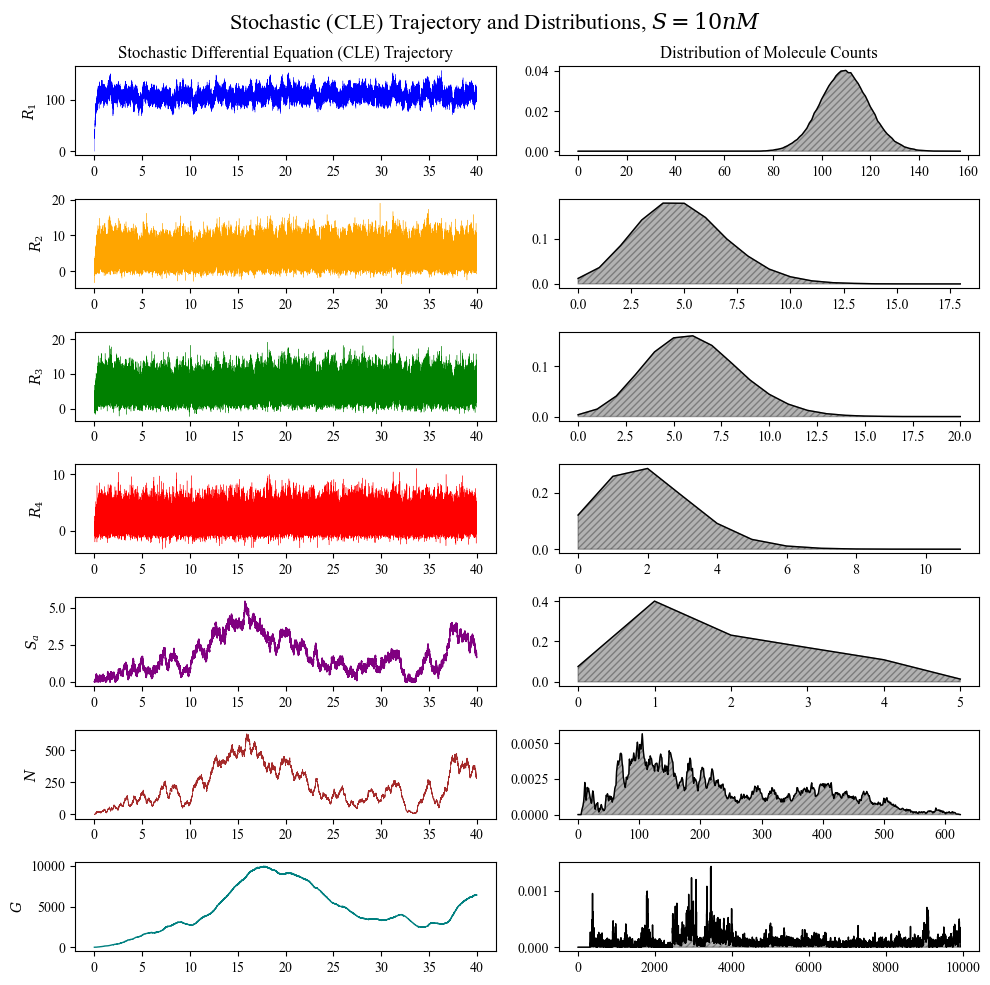

In [211]:
CLE_test_indices = np.where((t_SDE >= 2) & (t_SDE <= tmax))[0]

CLE_test_values = x_SDE[:, CLE_test_indices] # only consider the trajectory after time 2 to allow system to reach steady state and avoid initial transient effects
CLE_test_values = np.where(CLE_test_values < 0, 0, CLE_test_values) # set negative values to zero for histogram

CLE_max_values = np.max(CLE_test_values, axis=1).astype(int)

CLE_bin_step_size = 1
CLE_bins = [np.arange(-CLE_bin_step_size/2, max_val + 1 + CLE_bin_step_size/2, CLE_bin_step_size) for max_val in CLE_max_values] # bins for histogram, from -0.5 to max+0.5 with width 1

CLE_histograms = []
CLE_bin_edges_list = []

for n in range(7):
    hist, bin_edges = np.histogram(CLE_test_values[n,:], bins=CLE_bins[n], density=True)
    CLE_histograms.append(hist)
    CLE_bin_edges_list.append(bin_edges)

fig, axes = plt.subplots(7, 2, figsize=(10,10), dpi=100, layout='tight')

for n in range(7):
    axes[n,0].plot(t_SDE, x_SDE[n,:], color=colors[n], linewidth=plot_linewidths[n])
    axes[n,1].plot(CLE_bin_edges_list[n][:-1] + CLE_bin_step_size/2, CLE_histograms[n], color='black', linestyle='-', linewidth=1)
    axes[n,1].fill_between(CLE_bin_edges_list[n][:-1] + CLE_bin_step_size/2, CLE_histograms[n], alpha=0.3, color='black', hatch='/////', edgecolor='black')
    axes[n,0].set_ylabel(labels[n])

axes[0,0].set_title('Stochastic Differential Equation (CLE) Trajectory')
axes[0,1].set_title('Distribution of Molecule Counts')

fig.suptitle(r'Stochastic (CLE) Trajectory and Distributions, $S = 10 nM$', fontsize=16)
plt.savefig('Figures/CLE_trajectory_and_distributions.png', dpi=300, bbox_inches='tight')

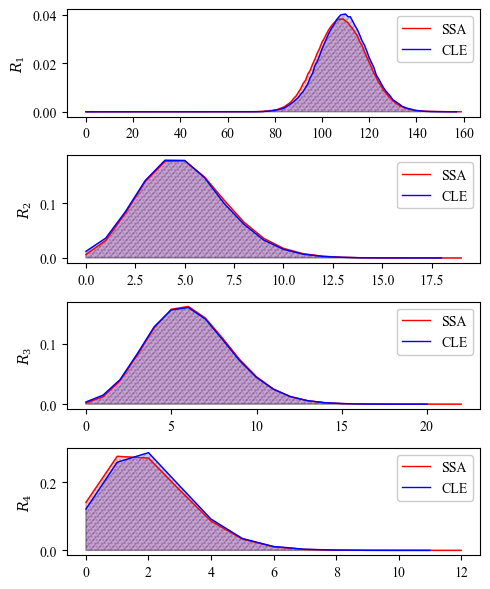

In [212]:
fig, axes = plt.subplots(4, 1, figsize=(5,6), dpi=100, layout='tight')

for n in range(4):
    axes[n].plot(SSA_bin_edges_list[n][:-1] + 0.5, SSA_histograms[n], color='red', linestyle='-', linewidth=1, label='SSA')
    axes[n].fill_between(SSA_bin_edges_list[n][:-1] + 0.5, SSA_histograms[n], alpha=0.2, color='red', hatch='.....', edgecolor='black')
    axes[n].plot(CLE_bin_edges_list[n][:-1] + CLE_bin_step_size/2, CLE_histograms[n], color='blue', linestyle='-', linewidth=1, label='CLE')
    axes[n].fill_between(CLE_bin_edges_list[n][:-1] + CLE_bin_step_size/2, CLE_histograms[n], alpha=0.2, color='blue', hatch='/////', edgecolor='black')
    axes[n].set_ylabel(labels[n])
    axes[n].legend(loc='upper right', fontsize=10, framealpha=1)

In [217]:
# calculate L2 error
L1_errors = []
L2_errors = []
for n in range(4):
    # Interpolate CLE histogram to SSA bin centers
    CLE_hist_interp = np.interp(SSA_bin_edges_list[n][:-1] + 0.5, CLE_bin_edges_list[n][:-1] + CLE_bin_step_size/2, CLE_histograms[n])
    L1_errors.append(np.sum(np.abs(SSA_histograms[n] - CLE_hist_interp)))
    L2_errors.append(np.sqrt(np.sum((SSA_histograms[n] - CLE_hist_interp)**2)))

L1_errors = np.array(L1_errors) * 100
L2_errors = np.array(L2_errors) * 100

print(f'L1 errors: {L1_errors[0]:.2f}%, {L1_errors[1]:.2f}%, {L1_errors[2]:.2f}%, {L1_errors[3]:.2f}%')
print(f'L2 errors: {L2_errors[0]:.2f}%, {L2_errors[1]:.2f}%, {L2_errors[2]:.2f}%, {L2_errors[3]:.2f}%')

L1 errors: 9.65%, 3.52%, 2.04%, 7.38%
L2 errors: 1.51%, 1.17%, 0.62%, 3.34%
